In [1]:
##############################################################################################################################################################################################################################################################
### Create the reference for all cells

In [2]:
import sys
print(sys.executable) # Run the program in the Xenium environment you created

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/bin/python


In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import h5py
import anndata as ad
import matplotlib.pyplot as plt
import warnings
import os
import squidpy as sq
import spatialdata as sd
import spatialdata_io as sio
import spatialdata_plot
from scipy import sparse
from pathlib import Path
import seaborn as sns

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from

In [4]:
sc.settings.verbosity = 3

In [6]:
### Make marker lists

#Import the marker list CSV
markers_df = pd.read_csv("Marker_Lists_v4.csv")

# Convert each column into a list, removing empty cells, and save them in a dictionary
marker_dict = {
    cell_type: markers_df[cell_type].dropna().tolist()
    for cell_type in markers_df.columns
}

# # Filter by markers actually present in the Xenium data
# marker_dict = {
#     cell_type: [
#         gene for gene in genes
#         if gene in adata_combined.var_names
#     ]
#     for cell_type, genes in marker_dict.items()
# }

custom_SC = {
    key: marker_dict[key]
    for key in xenium_config.custom_SC_keys
}

SC_neuron = {
    key: marker_dict[key]
    for key in xenium_config.SC_neuron_keys
}

NameError: name 'xenium_config' is not defined

In [7]:
### Load the preprocessed data
adata_combined = sc.read_h5ad("Processed/Xenium_preprocessed.h5ad")

In [8]:
### PCA for dimension reduction, then UMAP. 
### All markers
sc.pp.pca(adata_combined, n_comps=30) # Each cell gets represented by 30 PCs

# Which cells have expression profiles most similar to each other? 
# Cosine distance focuses strongly on the direction/pattern of expression rather than absolute magnitude.
# Smaller n_neighbours tends to emphasize very local structure; larger values smooth across broader cell populations.
sc.pp.neighbors(adata_combined, n_neighbors = 15, metric="cosine") 

# Leiden looks at the neighbor graph and labels communities of highly interconnected cells (clusters)
sc.tl.leiden(adata_combined, flavor="igraph", n_iterations=-1, resolution=0.5)

computing PCA
    with n_comps=30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:243: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")


    finished (0:00:02)
computing neighbors


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:46)
running Leiden clustering
    finished: found 17 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:08)


computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:01:25)


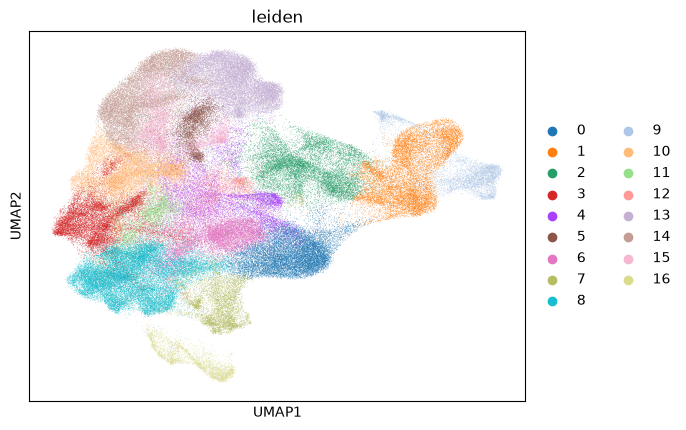

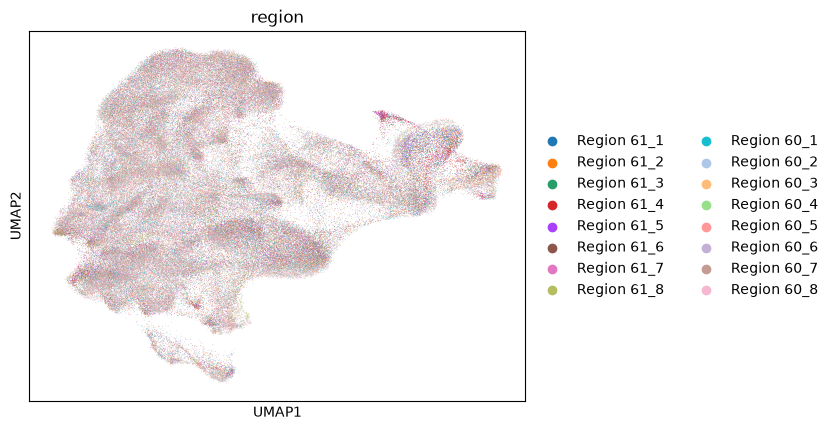

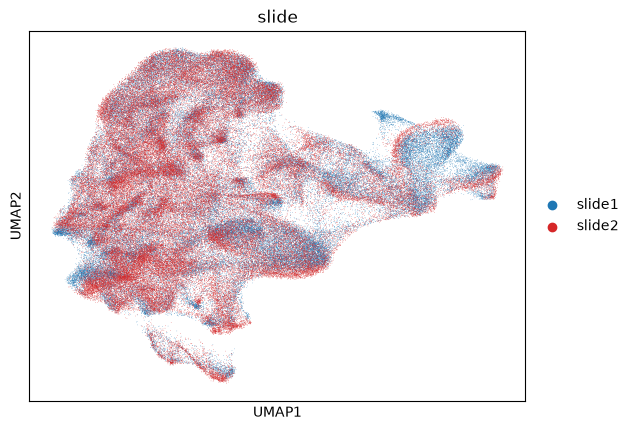

In [9]:
### UMAP
### All markers
sc.tl.umap(adata_combined)
sc.pl.umap(adata_combined, color="leiden")
sc.pl.umap(adata_combined, color="region") # colour by analysis region to check for region/sample effects

slide1 = [
    "Region 61_1",
    "Region 61_2",
    "Region 61_3",
    "Region 61_4",
    "Region 61_5",
    "Region 61_6",
    "Region 61_7",
    "Region 61_8"
]

slide2 = [
    "Region 60_1",
    "Region 60_2",
    "Region 60_3",
    "Region 60_4",
    "Region 60_5",
    "Region 60_6",
    "Region 60_7",
    "Region 60_8"
]

adata_combined.obs["slide"] = np.where(adata_combined.obs["region"].isin(slide1), "slide1", "slide2")
adata_combined.obs["dataset_group"] = pd.Categorical(adata_combined.obs["slide"],categories=["slide1", "slide2"],ordered=True)
sc.pl.umap(adata_combined, color="slide", palette=["#1f77b4", "#d62728"],show=False) # Colour by slide to look for batch effects
plt.savefig("Output/allcells_byslide.svg", bbox_inches="tight")
plt.show()

# Looking for animal effects is harder because not all regions contain sections from only 1 animal

In [10]:
adata_combined.write_h5ad("Processed/Xenium_allcell_reference.h5ad")

In [ ]:
# ### Feature plots

# # Get all genes from custom_SC, removing duplicates while preserving order
# all_custom_genes = list(dict.fromkeys(
#     gene
#     for genes in custom_SC.values()
#     for gene in genes
# ))

# # Keep only genes present in adata_neurons
# all_custom_genes = [
#     gene for gene in all_custom_genes
#     if gene in adata_combined.var_names
# ]

# for gene in all_custom_genes:

#     fig, axes = plt.subplots(
#         1, 2,
#         figsize=(10, 4)
#     )

#     # Feature expression
#     sc.pl.umap(
#         adata_combined,
#         color=gene,
#         layer="lognorm",
#         cmap="viridis",
#         frameon=False,
#         ax=axes[0],
#         show=False,
#         title=gene
#     )

#     # Leiden clusters
#     sc.pl.umap(
#         adata_combined,
#         color="leiden",
#         frameon=False,
#         ax=axes[1],
#         show=False,
#         title="Leiden"
#     )

#     # # Save individual feature plots
#     # # Output folder
#     # feature_plot_dir = Path("FeaturePlotsAllCells")
#     # feature_plot_dir.mkdir(exist_ok=True)
    
#     # # Get all genes from custom_SC, removing duplicates while preserving order
#     # all_custom_genes = list(dict.fromkeys(
#     #     gene
#     #     for genes in custom_SC.values()
#     #     for gene in genes
#     # ))
    
#     # # Keep only genes present in adata_neurons
#     # all_custom_genes = [
#     #     gene for gene in all_custom_genes
#     #     if gene in adata_combined.var_names
#     # ]
    
#     # for gene in all_custom_genes:
    
#     #     fig, axes = plt.subplots(
#     #         1, 2,
#     #         figsize=(10, 4)
#     #     )
    
#     #     # Feature expression
#     #     sc.pl.umap(
#     #         adata_combined,
#     #         color=gene,
#     #         layer="lognorm",
#     #         cmap="viridis",
#     #         frameon=False,
#     #         ax=axes[0],
#     #         show=False,
#     #         title=gene
#     #     )
    
#     #     # Leiden clusters
#     #     sc.pl.umap(
#     #         adata_combined,
#     #         color="leiden",
#     #         frameon=False,
#     #         legend_loc="on data",
#     #         ax=axes[1],
#     #         show=False,
#     #         title="Leiden"
#     #     )
    
#     #     plt.tight_layout()
    
#     #     # Save one figure per gene
#     #     fig.savefig(
#     #         feature_plot_dir / f"{gene}.png",
#     #         dpi=300,
#     #         bbox_inches="tight"
#     #     )
    
#     #     plt.show()
#     #     plt.close(fig)

    
#     plt.tight_layout()
#     plt.show()